## Example workflow for diversion (source-based) exposure time with dorado

This workbook calculates a **source-based (diversion) exposure time** in two dimensions using walk-data outputs from dorado. Instead of asking how long water takes to leave the whole system, we start from particles that were **released at the diversion (or any other single source location)** and ask **how long those flows remain in each area** of the domain.

To use this notebook, we need `walk_data` and `model_variables` that were created with `DORADO-01-unstructured_grid_exposure_time.ipynb`, using an initial particle seeding at the diversion.

For your own implementation with other models, `walk_data`, `elevation` (rasterized), and `regions` can be created using `dorado.particle_track.py` and `dorado.routines.py` following the methods of `unstructured_grid_Delft3dFM.ipynb` or `unstructured_grid_anuga.ipynb`.

### Import necessary dependencies

In [2]:
import os
import sys
import numpy as np
import json
from pathlib import Path
import dorado
from matplotlib import pyplot as plt
import dorado.spatial as spat
import dorado.particle_track as pt

if str(Path.cwd().parent) not in sys.path:
    sys.path.append(str(Path.cwd().parent))

from src.dorado_utils import from_source_exposure

### Set up model names and folders
First, we begin by calling the folder where *dorado* outputs and HydroShare files were saved. The `model_run` identifier is shared across the whole notebook so every load/save points at the same scenario.

In [ ]:
PROJECT_ROOT = Path.cwd().parent
# Core run identifier shared across the notebook
model_run = "diversion_2013_01"

path2folder = PROJECT_ROOT / "outputs" / "dorado" / model_run
path2folder.mkdir(parents=True, exist_ok=True)

### Load Variables

Now we load walk data that was output by `dorado.particle_track()` (with particles seeded at the diversion) as well as variables that were created while running the Delft3D unstructured grid notebook (`unstructured_grid_Delft3dFM.ipynb`). These are the rasterized versions of variables.

- `walk_data` dictionary of all x and y locations and travel times (`xinds`, `yinds`, `travel_times`) for particles released at the diversion, created with `dorado.particle_track.py` and `dorado.routines.py`
- `elevation` terrain or bathymetry grid which is used to define domain shape
- `regions` binary mask (same shape as `elevation`) marking the valid region of interest — the water body the diversion discharges into (1 = region of interest, 0 = ignore).

In [4]:

with open(PROJECT_ROOT / "outputs" / "dorado" / "multi_source" / f'{model_run}' / f'{model_run}_WalkData.txt', 'r') as f:
    walk_data = json.load(f)
model_variables = np.load(PROJECT_ROOT / "outputs" / "dorado" /"multi_source" / f'{model_run}' / f'{model_run}_Exposure.npz')
elevation = model_variables['elevation']


notebooks_data = PROJECT_ROOT / "notebooks" / "data"
celltype_initial = np.genfromtxt(notebooks_data / "cell_type_all_100m.csv", delimiter=",")
regions = np.genfromtxt(notebooks_data / "cell_type_all_100m_roi.csv", delimiter=",")

#### (Optional) Whole-domain exposure time for the diversion flows
Before looking at how long the flows sit in each *area*, it can help to see how long the diversion-released particles take to leave the region of interest as a whole. `dorado.particle_track.exposure_time()` returns the exposure time of every particle in `walk_data` for the region defined by `regions`.

In [5]:
exposure_times = pt.exposure_time(walk_data, regions)

100%|##########| 1712/1712 [00:04<00:00, 398.80it/s]


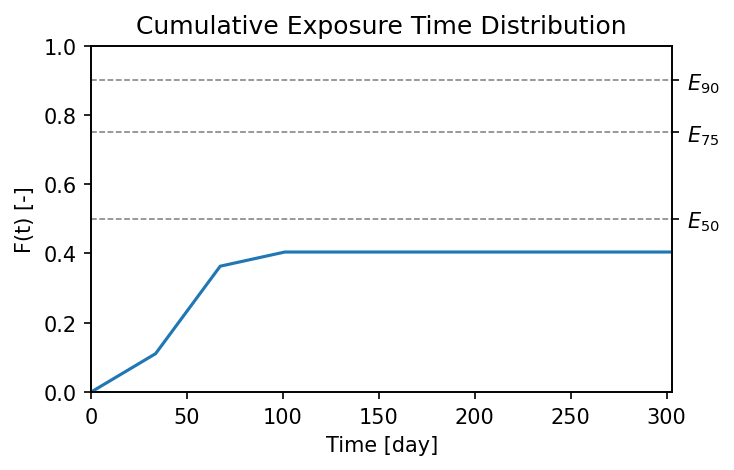

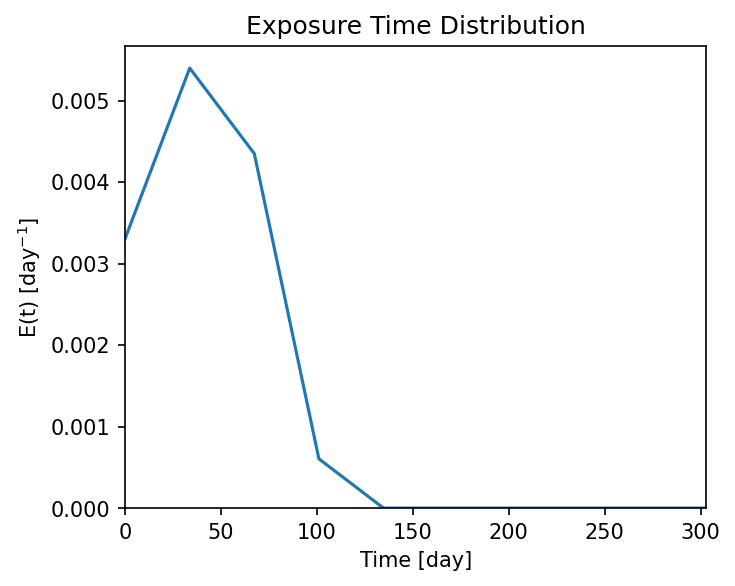

In [6]:
timedelta = 86400  # timestep of random walk in seconds (1 day = 86400 s)

exposure_times_plot = dorado.routines.plot_exposure_time(walk_data,
                                                         exposure_times,
                                                         f'{path2folder}/figs',
                                                         timedelta=timedelta,   # timestep for model in seconds
                                                         nbins=10,              # binning for the CDF
                                                         uniform_timesteps=True,# discrete/unsteady timestep handling
                                                         show_thresholds=True)  # print/plot E50, E75, E90

## Area exposure time for diversion flows

Now we want to know, for the water that leaves the diversion, **how long it lingers in each area** of the domain. We do this by laying a grid of `chunks` over the domain and, for every chunk, measuring the exposure time of the diversion-released particles *within that chunk only*.

This is a source-based cousin of `dorado.spatial.localized()`. The key difference:
- `spat.localized()` **re-seeds** particles inside each chunk and measures how long they stay in that chunk.
- Here we keep the **full set of diversion-released particles** in `walk_data` and ask, chunk by chunk, how long those flows remain in that area. Every particle came from the diversion, so we never subset by starting chunk.

<center><figure>
<img src="figs/schematic_transport_times_localized.png" class="bg-primary mb-1" width="500px", align="center">
<figcaption align="center"> Figure 1. Area (localized) exposure time schematic. </figcaption>
</figure><center>

#### Resolution Factor
Finding the exposure time for each rasterized cell is computationally expensive, so we provide a `resolution_factor`, which sets how much we rasterize by. Each chunk is `resolution_factor` **x** `resolution_factor` cells, with the exception of any trailing row/column that does not divide evenly (kept in mind when interpreting figures). The number of chunks is `rows // resolution_factor` by `cols // resolution_factor`.

Original grid size: (1076, 571)
Rasterized grid size: (43, 22)


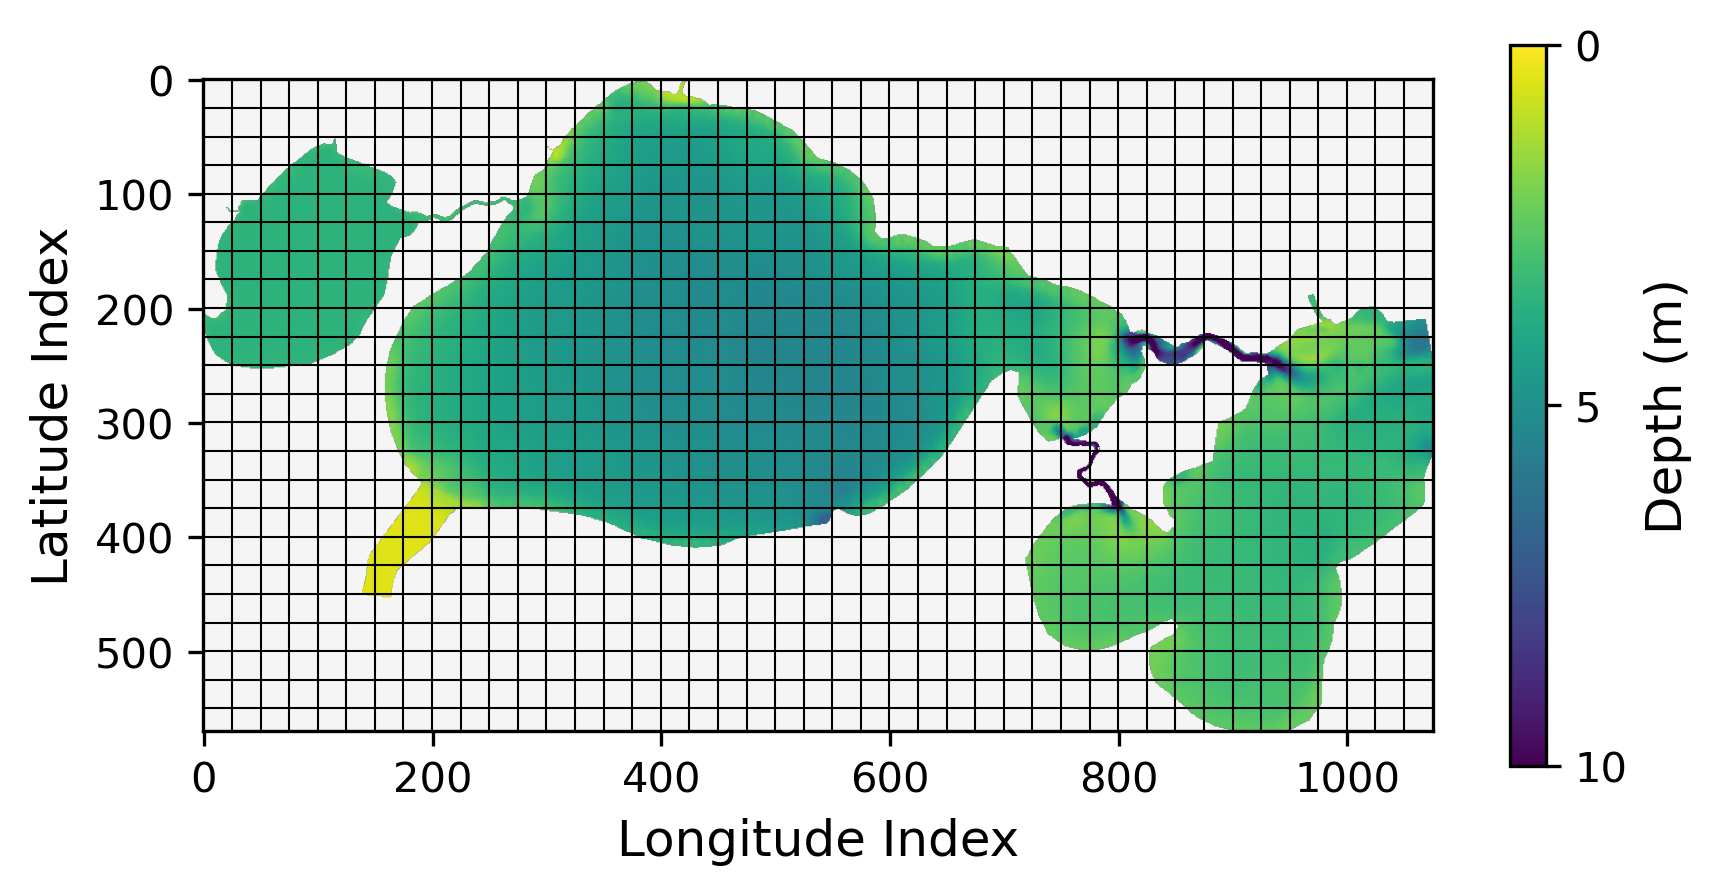

In [ ]:
resolution_factor = 25
rows, cols = elevation.shape
print(f'Original grid size: ({cols + 1}, {rows + 1})')  # +1 accounts for zero indexing
n_chunks_rows = rows // resolution_factor
n_chunks_cols = cols // resolution_factor
print(f'Rasterized grid size: ({n_chunks_cols}, {n_chunks_rows})')

# Figure to visualize the chunk grid over the domain
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
cax = ax.imshow(elevation, vmin=-10, vmax=0, cmap='viridis')
cbar = fig.colorbar(cax, ax=ax, label='Depth (m)', shrink=0.6)
cbar.ax.set_ylabel('Depth (m)', fontsize=12)
cbar.set_ticks([0, -5, -10])
cbar.set_ticklabels(['0', '5', '10'])
ax.set_xlabel('Longitude Index', fontsize=12)
ax.set_ylabel('Latitude Index', fontsize=12)
ax.set_facecolor('whitesmoke')
for y in range(0, rows, resolution_factor):
    ax.axhline(y - 0.5, color='black', linewidth=0.5)
for x in range(0, cols, resolution_factor):
    ax.axvline(x - 0.5, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

#### Definition: `from_source_exposure()`
We use a reusable helper from `src/dorado_utils.py` that walks the chunk grid and, for each chunk that overlaps the region of interest, builds a chunk-only mask and calls `dorado.particle_track.exposure_time()` on the full source-released `walk_data`. Chunks that do not touch the region of interest are stored as `np.nan` so that the returned list is a complete, row-major grid of chunks (matching the ordering `dorado.spatial.compute_thresholds()` expects).

Now we run it. This returns a list of exposure times for the diversion flows in each chunk (or `np.nan` where a chunk is outside the region of interest).

In [8]:
diversion_area_exposure = from_source_exposure(walk_data, elevation, regions,
                                            resolution_factor=resolution_factor)

100%|##########| 1712/1712 [00:04<00:00, 406.78it/s]


We can save the per-area exposure data so it does not need to be recomputed. It is written into the `model_run` output folder.

In [9]:
json.dump(diversion_area_exposure,
          open(path2folder / f'{model_run}_ExposureData_diversion.txt', 'w'))

Now that we have a list of exposure times for the diversion flows in each chunk, we want to find how long it takes to reach our three thresholds ($E_{50}$, $E_{75}$, $E_{90}$). `dorado.spatial.compute_thresholds()` calculates these thresholds and places them into a gridded array matching the shape of `elevation`, creating a spatial map.

We smooth the map using a Mean Average Deviation filter, which needs two variables:
- `window_size` number of adjacent gridcells used to smooth data
- `threshold` number of gridcells used to suppress outliers

Along with `exposure_data`, `elevation`, `timedelta`, and `resolution_factor`, this outputs three 2D arrays: `E50`, `E75`, and `E90`.

- $E_{50}$: the time it takes for 50% of the diversion flow to leave the area
- $E_{75}$: the time it takes for 75% of the diversion flow to leave the area
- $E_{90}$: the time it takes for 90% of the diversion flow to leave the area

#### Area Exposure Time Figure
Now we plot the three spatial arrays. We define a few plotting variables:
- `title` the label on the colorbar
- `cmap` the colormap (a matplotlib colormap here; [cmocean](https://matplotlib.org/cmocean/) also works well)
- `max_exposure` the maximum time the colorbar goes to (adjust to your model's timeframe; source-based area exposure is usually short)
- `cbar_levels` the number of levels to split the colorbar by

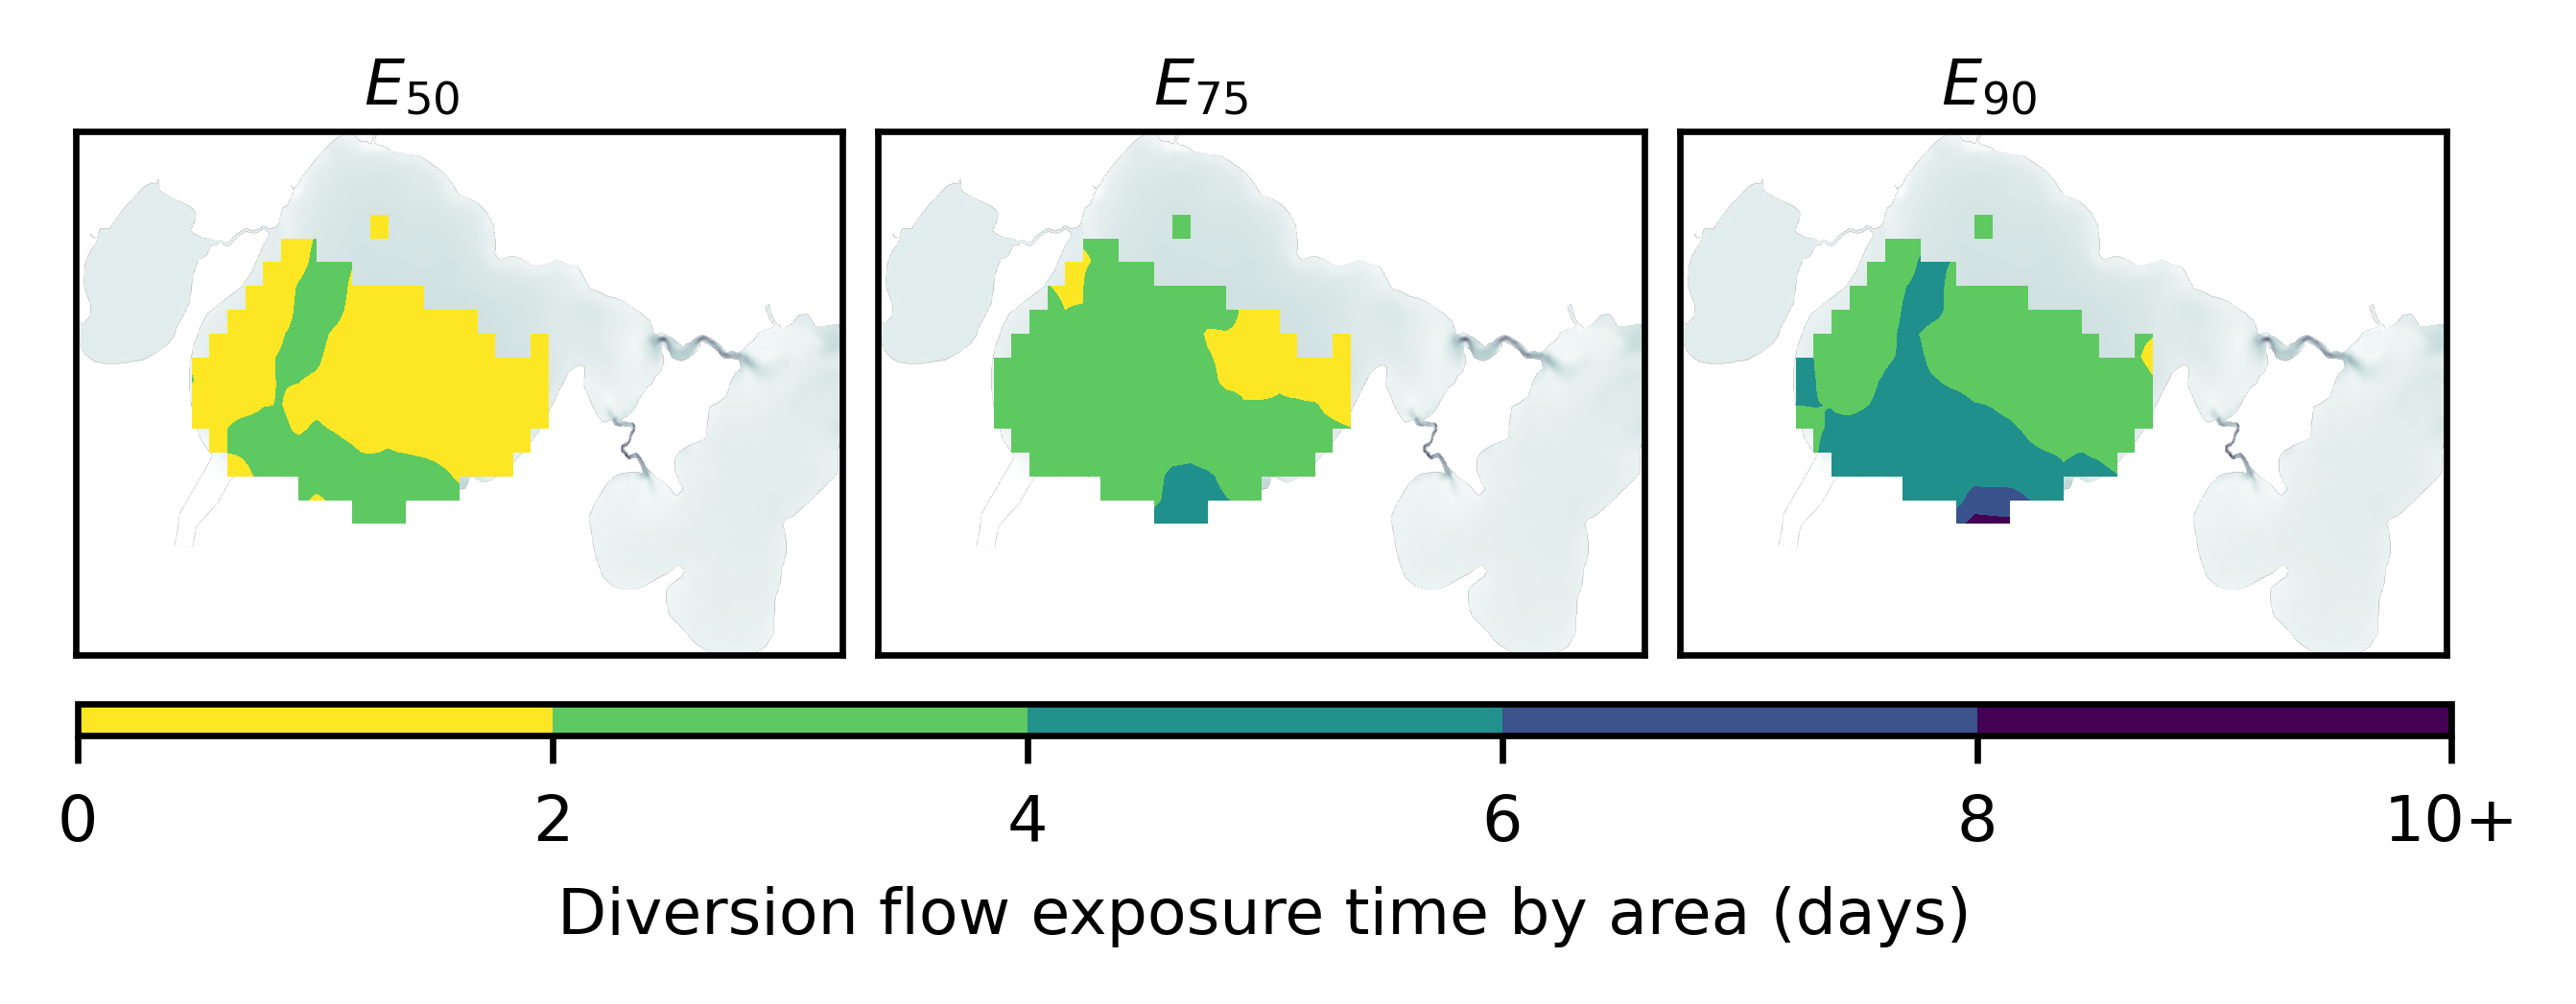

In [12]:
window_size = 3
threshold = 3

E50, E75, E90 = spat.compute_thresholds(
    exposure_data=diversion_area_exposure,
    elevation=elevation,
    timedelta=timedelta,
    resolution_factor=resolution_factor,
    window_size=window_size,
    threshold=threshold)


title = 'Diversion flow exposure time by area (days)'
cmap = plt.get_cmap('viridis_r')
max_exposure = 10
cbar_levels = 6
diversion_plot = spat.plot_spatial(
    exposure_maps=[E50, E75, E90],
    elevation=elevation,
    max_exposure=max_exposure,
    cbar_levels=cbar_levels,
    cmap=cmap,
    title=title)

This map shows where diversion-released water lingers longest. Zones of increased exposure time are areas where local flows trap the diverted water, while low values mark areas the flow passes through quickly.

If you have any questions or need help with implementation to your model, please do not hesitate to contact Caitlin R. R. Turner at cturn65@lsu.edu

#### **Cited**:
Turner, C. R. R., & Hiatt, M. (2025a). Water exposure time distributions controlled by freshwater releases in a semi-enclosed estuary. Water Resources Research, 61 (7), e2025WR040287, https://doi.org/10.1029/2025WR040287

Turner, C. R. R., & Hiatt, M. (2025b). Water exposure time distributions controlled by freshwater releases in a semi-enclosed estuary published in water resources research wrr 2025 data. [Dataset]. Hydroshare, https://doi.org/10.4211/hs.f1c83ff830bb47c5a7c84e6f5217ea5c

#### **Acknowledgments:**
This work has been partially supported with funding provided by the Louisiana Sea Grant College Program (LSG) under its Competitive Research Program (Project ID: R/TMA-03) and NOAA Award No. NA18OAR4170098, and through the US Department of Defense/Army Engineer Research and Development Center (ERDC) under Contract No. W912HZ2220005. Additional support was provided from the National Science Foundation (NSF) through Open Earthscape (Collaborative Research: Frameworks: OpenEarthscape - Transformative Cyberinfrastructure for Modeling and Simulation in the Earth-Surface Science Communities) under its Summer Research Scholars Program under award No. 2104102.